# Modelo nulo de las migraciones internacionales
*Tests de permutación (QAP) sobre el stock migratorio de la ONU, 1990-2024*

Este notebook evalúa tres hipótesis sobre qué determina las migraciones internacionales. En todas, el stock migratorio se modela como un **grafo dirigido y ponderado**: los nodos son países y la arista `i → j` pesa la cantidad de personas nacidas en `i` que viven en `j`.

| | Hipótesis | Vínculo que se pone a prueba |
|---|---|---|
| **H1** | Dominancia geográfica | Los países comparten frontera terrestre |
| **H2** | Afinidad cultural | Idioma oficial en común o lazos coloniales (origen en África) · idioma en común o pertenencia a la Commonwealth (origen en la Commonwealth) |
| **H3** | Asimetría económica | El destino es más desarrollado que el origen |

## Por qué un test de permutación

Las tres hipótesis tienen la misma forma: *¿hay más migración entre los pares de países que tienen un vínculo que entre los que no lo tienen?* La forma obvia de responderla sería comparar los dos grupos de pares con un test clásico (t, chi², regresión). Pero esos tests suponen que cada par es una observación independiente, y en una red no lo es: todos los pares con destino Estados Unidos comparten su atractivo, y todos los que salen de India comparten su emigración. Con datos así, un test clásico da p-valores demasiado chicos.

El **test de permutación QAP** (*Quadratic Assignment Procedure*, procedimiento de asignación cuadrática) resuelve ese problema. En lugar de suponer una distribución teórica, la construye a partir de los propios datos:

1. Se calcula un estadístico con los datos reales: cuánta migración cae sobre los pares con vínculo.
2. Se reasignan al azar las etiquetas de los países (qué país es cuál) y se recalcula el estadístico. Cada país se mueve con su fila y su columna completas, así que conserva todo su perfil migratorio. Lo único que se rompe es la correspondencia entre la red de migraciones y la red de vínculos.
3. Se repite el paso 2 muchas veces (acá, 10.000). Los valores obtenidos forman la **distribución nula**: lo que se vería si el vínculo no tuviera nada que ver con la migración.
4. El **p-valor** es la proporción de permutaciones que igualan o superan al valor real.

```latex
p = \frac{1 + \#\{T_{perm} \ge T_{obs}\}}{1 + N_{perm}}
```

## Los tres estadísticos

Los tres miden la migración sobre los pares con vínculo, y en los tres un valor alto va en contra de H₀:

| | Estadístico | Qué mide |
|---|---|---|
| **T1** | Parte del stock que fluye entre pares con vínculo | Volumen |
| **T2** | Proporción de pares con vínculo que tienen algún migrante registrado | Existencia de la conexión |
| **T3** | Promedio de log₁₀(1 + migrantes) en los pares con vínculo | Intensidad típica del flujo |

T1 depende mucho de unos pocos flujos enormes (como México → Estados Unidos). T2 y T3 miran el comportamiento típico de los pares, por eso conviene leer los tres juntos.

## Estructura del notebook

- **0. Preparación:** datos y funciones comunes a las tres hipótesis.
- **1. Hipótesis 1:** el test completo, con todos los detalles.
- **2. Hipótesis 2:** refiere a la hipótesis 1 en lo que es igual y explica las diferencias, para dos casos (África y Commonwealth).
- **3. Hipótesis 3:** igual que la anterior, con un vínculo dirigido.
- **4. Resumen:** todos los resultados en una tabla.

---
# 0. Preparación
## 0.1 Librerías y parámetros

In [1]:
import io, json, warnings
import xml.etree.ElementTree as ET
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

# ---- Parámetros del análisis ----
AÑO_PRINCIPAL = "2024"      # año que se analiza
N_PERM        = 10_000      # permutaciones por test (bajar a 2_000 para pruebas rápidas)
SEMILLA       = 42          # fija el azar: los resultados son reproducibles
ALFA          = 0.05        # nivel de significación

# ---- Fuentes de datos ----
URL_ONU   = ("https://www.un.org/development/desa/pd/sites/www.un.org.development.desa.pd/"
             "files/undesa_pd_2024_ims_stock_by_sex_destination_and_origin.xlsx")
BASE_GH   = "https://raw.githubusercontent.com/RexCaecos/ciencia_redes_uba/main/"
URL_AUX   = BASE_GH + "aux_poblacion_coord.xlsx"           # qué entidades son países válidos
URL_FRONT = BASE_GH + "paises_fronteras_completo.json"     # fronteras terrestres
URL_M49   = "https://raw.githubusercontent.com/RexCaecos/evolucion_redes_migratorias/main/fuentes_de_datos/m49.csv"
URL_CLDR  = "https://raw.githubusercontent.com/unicode-org/cldr/release-48-2/common/supplemental/supplementalData.xml"
URL_COLDAT = "https://dataverse.harvard.edu/api/v1/access/datafile/7416947?gbrecs=false"
URL_BM    = "https://api.worldbank.org/v2/country/all/indicator"
HEADERS   = {"User-Agent": "Mozilla/5.0"}   # la web de la ONU rechaza pedidos sin user-agent

## 0.2 Descarga de datos

`descargar` baja cada archivo. Si una fuente falla, avisa desde dónde bajarlo y pide subirlo a mano en Colab.

**Códigos de país.** Todo el notebook identifica a los países con su código **ISO2** (`AR`, `ES`, `NA`...). Dos fuentes vienen con otro código y se traducen una sola vez, al cargarlas: la ONU usa códigos numéricos M49 y el JSON de fronteras usa ISO3. La traducción sale de la tabla de equivalencias que trae el propio archivo del CLDR (`codeMappings`).

**Namibia.** Su código ISO2 es `"NA"`, y pandas lo lee como dato faltante al cargar un CSV. Por eso `m49.csv` se lee con `keep_default_na=False`: así el problema se evita en la carga y no hay que corregir nada después.

In [2]:
def descargar(url, etiqueta):
    """Descarga una URL. Si falla, pide subir el archivo a mano (Colab)."""
    try:
        r = requests.get(url, headers=HEADERS, timeout=120)
        r.raise_for_status()
        print(f"OK  {etiqueta}: {len(r.content)/1e6:.2f} MB")
        return r.content
    except Exception as e:
        print(f"ERROR descargando {etiqueta}: {e}")
        print(f"Descargalo a mano desde:\n  {url}\ny subilo acá.")
        from google.colab import files
        subido = files.upload()
        return next(iter(subido.values()))

bytes_onu    = descargar(URL_ONU, "ONU - stock migratorio 2024")
bytes_aux    = descargar(URL_AUX, "Tabla auxiliar de países")
bytes_front  = descargar(URL_FRONT, "Fronteras entre países")
bytes_m49    = descargar(URL_M49, "Códigos M49 / ISO")
bytes_cldr   = descargar(URL_CLDR, "Unicode CLDR 48.2 (idiomas oficiales)")
bytes_coldat = descargar(URL_COLDAT, "COLDAT (díadas coloniales)")

# Tabla de equivalencias del CLDR: ISO2 <-> ISO3 <-> M49
raiz_cldr = ET.fromstring(bytes_cldr)
actuales = {t.get("type") for t in raiz_cldr.findall(".//territoryInfo/territory")}
m49_a_iso2, iso3_a_iso2 = {}, {}
for t in raiz_cldr.findall(".//codeMappings/territoryCodes"):
    iso2, num, iso3 = t.get("type"), t.get("numeric", ""), t.get("alpha3")
    if len(iso2) == 2 and iso2.isalpha():
        if iso3:
            iso3_a_iso2[iso3] = iso2
        if num.isdigit() and (int(num) not in m49_a_iso2 or iso2 in actuales):   # ante códigos viejos repetidos, gana el vigente
            m49_a_iso2[int(num)] = iso2
assert m49_a_iso2 and iso3_a_iso2, "No encontré la tabla codeMappings en el XML del CLDR"

# Fronteras: el JSON viene en ISO3 y se pasa a ISO2 acá, una sola vez
fronteras = {iso3_a_iso2[k]: {**v, "vecinos": [iso3_a_iso2[x] for x in v.get("vecinos", []) if x in iso3_a_iso2]}
             for k, v in json.loads(bytes_front).items() if k in iso3_a_iso2}

df_m49 = pd.read_csv(io.BytesIO(bytes_m49), keep_default_na=False, na_values=[""])   # "NA" = Namibia
assert "NA" in set(df_m49["iso2_m49"]), "Falta Namibia: m49.csv debe leerse con keep_default_na=False"

OK  ONU - stock migratorio 2024: 6.01 MB
OK  Tabla auxiliar de países: 1.62 MB
OK  Fronteras entre países: 0.03 MB
OK  Códigos M49 / ISO: 0.02 MB
OK  Unicode CLDR 48.2 (idiomas oficiales): 0.40 MB
OK  COLDAT (díadas coloniales): 0.05 MB


## 0.3 La matriz de migraciones W

`W[año][i, j]` es la cantidad de personas nacidas en `i` que residen en `j`. Se arma desde la tabla de la ONU, quedándose solo con países (no regiones ni agregados) según el mismo criterio del TP. La diagonal vale 0.

In [3]:
# ONU -> tabla con códigos de origen y destino y una columna por año
raw = pd.read_excel(io.BytesIO(bytes_onu), sheet_name="Table 1", engine="openpyxl")
raw = raw.iloc[9:, :15].reset_index(drop=True)       # zona de datos (ambos sexos)
raw.columns = raw.iloc[0].astype(str)                # primera fila = encabezados
raw = raw[1:].reset_index(drop=True)

cols = [c[:-2] if c.endswith(".0") else c for c in raw.columns]
idx_codigos = [i for i, c in enumerate(cols) if "code" in c.lower()]
assert len(idx_codigos) == 2, f"No encontré las 2 columnas de código: {cols}"
cols[idx_codigos[0]], cols[idx_codigos[1]] = "cod_des", "cod_ori"   # primero destino, luego origen
raw.columns = cols
años = cols[7:15]
assert all(a.isdigit() for a in años), f"Columnas de años inesperadas: {años}"
for c in años + ["cod_des", "cod_ori"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
onu = raw[["cod_ori", "cod_des"] + años].dropna(subset=["cod_ori", "cod_des"]).fillna(0)
onu[["cod_ori", "cod_des"]] = onu[["cod_ori", "cod_des"]].astype(int)

# Países válidos y su código ISO2
df_regiones = pd.read_excel(io.BytesIO(bytes_aux), sheet_name="Regiones", header=1)
status_validos = ["Member State", "CN Province", "CN Special Administrative Region",
                  "Occupied Palestinan Territory", "NL Self-Governing Territory",
                  "DK Self-Governing Territory", "The City of Vatican"]
paises = df_regiones[(df_regiones["Type"] == "Country/Area") & (df_regiones["status_un"].isin(status_validos))].copy()
paises["Location code"] = paises["Location code"].astype(int)
cod2iso = {c: m49_a_iso2[c] for c in paises["Location code"] if c in m49_a_iso2}
print("Países válidos sin código ISO2 (quedan afuera):",
      sorted(paises.loc[~paises["Location code"].isin(cod2iso), "Region, subregion, country or area *"]))

# Matrices W por año
solo_paises = onu[onu["cod_ori"].isin(cod2iso) & onu["cod_des"].isin(cod2iso)].copy()
solo_paises["iso_ori"] = solo_paises["cod_ori"].map(cod2iso)
solo_paises["iso_des"] = solo_paises["cod_des"].map(cod2iso)
nodos = sorted(set(solo_paises["iso_ori"]) | set(solo_paises["iso_des"]))
pos = {iso: k for k, iso in enumerate(nodos)}
n = len(nodos)

W_por_año = {}
for a in años:
    M = np.zeros((n, n))
    np.add.at(M, (solo_paises["iso_ori"].map(pos).to_numpy(), solo_paises["iso_des"].map(pos).to_numpy()),
              solo_paises[a].to_numpy())
    np.fill_diagonal(M, 0)
    W_por_año[a] = M
W = W_por_año[AÑO_PRINCIPAL]

def submatriz(universo, año=AÑO_PRINCIPAL):
    """W restringida a una lista de países (ISO2), en ese orden."""
    ix = [pos[i] for i in universo]
    return W_por_año[año][np.ix_(ix, ix)]

print(f"Países: {n} · años: {años}")
print(f"Stock total {AÑO_PRINCIPAL}: {W.sum():,.0f} migrantes · pares con migración: {(W > 0).sum():,} "
      f"(densidad {(W > 0).sum() / (n * (n - 1)):.3f})")

Países válidos sin código ISO2 (quedan afuera): []
Países: 202 · años: ['1990', '1995', '2000', '2005', '2010', '2015', '2020', '2024']
Stock total 2024: 278,458,411 migrantes · pares con migración: 8,417 (densidad 0.207)


## 0.4 El test: cómo funciona el código

Las tres hipótesis usan las mismas funciones:

- **`qap(W, C, filas, cols, grupos)`** corre el test. `W` es la matriz de migraciones y `C` la de vínculos (verdadero o falso para cada par). `filas` y `cols` permiten estudiar solo una parte de la red, por ejemplo los orígenes africanos (por defecto, toda la red).
    - Primero arma tres versiones de `W`: los migrantes, si hay migración (`W > 0`) y `log10(1 + W)`. Cada estadístico es la suma de una de ellas sobre los pares con vínculo, dividida por el total que corresponde.
    - En cada permutación genera un orden al azar `p` de los países y reetiqueta filas y columnas de `W` con ese mismo orden. `C` queda fija. Reetiquetar `W` o reetiquetar `C` da la misma distribución nula; se reetiqueta `W` porque así la cantidad de pares con vínculo del bloque estudiado es siempre la misma.
    - Con `grupos=None` la permutación es global: cualquier país puede tomar la etiqueta de cualquier otro. Con `grupos` (un rótulo por país), solo se mezclan países del mismo grupo. Se usa en la hipótesis 2.
    - La permutación se aplica siempre a la matriz completa (cuadrada, con todos los países) y recién después se toma el bloque `filas` × `cols`. Así origen y destino se reetiquetan con el mismo orden aunque el bloque estudiado sea rectangular.
- **`resumen`** arma la tabla de resultados: valor observado, media bajo H₀, cuántas veces mayor es el observado (`ratio_obs/nula`), z y p-valor.
- **`graficar_nulos`** dibuja la distribución nula de cada estadístico (histograma azul) y el valor observado (línea roja). Si la línea queda lejos, a la derecha del histograma, la realidad es muy distinta de lo esperable por azar.

Con 10.000 permutaciones el p-valor más chico posible es 1/10.001 ≈ 0,0001. Si un resultado da eso, ninguna permutación alcanzó el valor observado: el gráfico lo muestra como "p < 0,0001".

In [4]:
NOMBRES_T = ["T1 · parte del stock", "T2 · pares con migración", "T3 · media log10(1+x)"]

def perm_por_grupos(grupos, rng):
    """Permutación que solo mezcla países del mismo grupo."""
    p = np.arange(len(grupos))
    for g in np.unique(grupos):
        ix = np.where(grupos == g)[0]
        p[ix] = rng.permutation(ix)
    return p

def qap(W, C, filas=None, cols=None, grupos=None, n_perm=N_PERM, semilla=SEMILLA):
    """
    Test QAP del bloque W[filas, cols] contra el vínculo C[filas, cols].
    Devuelve (observado, nulos): arrays de forma (3,) y (n_perm, 3) con T1, T2, T3.
    """
    n = len(W)
    filas = np.arange(n) if filas is None else np.asarray(filas)
    cols = np.arange(n) if cols is None else np.asarray(cols)
    S = np.stack([W, (W > 0).astype(float), np.log10(1 + W)])   # volumen, existencia, intensidad
    Cb = C[np.ix_(filas, cols)].astype(float)
    k = Cb.sum()                                                  # pares con vínculo (fijo)
    assert k > 0, "No hay pares con vínculo en el bloque estudiado"

    def estadisticos(p):
        Sb = S[:, p[filas]][:, :, p[cols]]                        # W reetiquetada con el orden p
        return (Sb * Cb).sum(axis=(1, 2)) / np.array([Sb[0].sum(), k, k])

    rng = np.random.default_rng(semilla)
    obs = estadisticos(np.arange(n))                              # sin permutar = datos reales
    nulos = np.empty((n_perm, 3))
    for b in range(n_perm):
        p = rng.permutation(n) if grupos is None else perm_por_grupos(grupos, rng)
        nulos[b] = estadisticos(p)
    return obs, nulos

def p_valores(obs, nulos):
    return (1 + (nulos >= obs).sum(axis=0)) / (1 + len(nulos))

def resumen(obs, nulos, etiquetas=NOMBRES_T):
    pv = p_valores(obs, nulos)
    sd = nulos.std(axis=0)
    return pd.DataFrame({
        "estadístico": etiquetas,
        "observado": obs,
        "media_nula": nulos.mean(axis=0),
        "ratio_obs/nula": obs / nulos.mean(axis=0),
        "z": np.where(sd > 0, (obs - nulos.mean(axis=0)) / np.where(sd > 0, sd, 1), np.nan),
        "p_valor": pv,
        "rechaza_H0": pv < ALFA,
    })

def formato_p(p, n_perm):
    return f"p < {1 / (n_perm + 1):.4f}" if p <= 1 / (n_perm + 1) else f"p = {p:.4f}"

def graficar_nulos(obs, nulos, titulo):
    pv = p_valores(obs, nulos)
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
    for k, ax in enumerate(axs):
        ax.hist(nulos[:, k], bins=50, color="#9bb7d4", edgecolor="white", label="permutaciones (H₀)")
        ax.axvline(obs[k], color="crimson", lw=2, label="observado")
        ax.set_title(f"{NOMBRES_T[k]}\n{formato_p(pv[k], len(nulos))}", fontsize=11)
        ax.set_xlabel("valor del estadístico")
    axs[0].set_ylabel("cantidad de permutaciones")
    axs[0].legend(fontsize=9)
    fig.suptitle(f"{titulo} · distribución bajo H₀ ({len(nulos):,} permutaciones) · año {AÑO_PRINCIPAL}", y=1.06)
    plt.tight_layout()
    plt.show()

---
# 1. Hipótesis 1 · Dominancia geográfica

**Pregunta:** ¿el stock de migrantes entre dos países depende de que compartan frontera terrestre?

- **H₀:** la adyacencia no tiene relación con el stock migratorio. Las migraciones se reparten entre pares de países sin relación con el mapa de fronteras.
- **H₁:** los pares limítrofes tienen más migración que la esperable bajo H₀.

**El vínculo** es la matriz de adyacencia `A`: `A[i, j]` es verdadero si `i` y `j` comparten frontera. Es simétrica y se arma desde el JSON de fronteras.

**Qué se permuta:** todos los países entre sí (permutación global), porque se estudian todos los pares de la red. Cada permutación conserva la matriz de migraciones completa y la forma del mapa de fronteras (cantidad de pares limítrofes y de vecinos de cada país). Solo rompe la correspondencia entre qué país es cuál en cada matriz.

## 1.1 Matriz de adyacencia

In [5]:
A = np.zeros((n, n), dtype=bool)
for iso, info in fronteras.items():
    if iso in pos:
        for v in info.get("vecinos", []):
            if v in pos:
                A[pos[iso], pos[v]] = True
A = A | A.T                      # la frontera es simétrica (corrige pares cargados en un solo sentido)
np.fill_diagonal(A, False)
tipo = np.array([fronteras.get(iso, {}).get("tipo", "desconocido") for iso in nodos])

print(f"Pares limítrofes: {A.sum() // 2} · países sin entrada en el JSON: {sorted(set(nodos) - set(fronteras))}")
print(f"Los pares limítrofes son el {A.sum() / (n * (n - 1)):.2%} de los pares posibles "
      f"y concentran el {W[A].sum() / W.sum():.1%} del stock migratorio de {AÑO_PRINCIPAL}.")

Pares limítrofes: 311 · países sin entrada en el JSON: ['AG', 'AW', 'CW', 'GL', 'HK', 'MO', 'SX']
Los pares limítrofes son el 1.53% de los pares posibles y concentran el 35.6% del stock migratorio de 2024.


## 1.2 Test

In [6]:
obs_h1, nulos_h1 = qap(W, A)
res_h1 = resumen(obs_h1, nulos_h1)
res_h1.round(4)

,estadístico,observado,media_nula,ratio_obs/nula,z,p_valor,rechaza_H0
0,T1 · parte del stock,0.3559,0.0151,23.5272,37.1420,0.0001,True
1,T2 · pares con migración,0.9003,0.2072,4.3449,31.0781,0.0001,True
2,T3 · media log10(1+x),3.9431,0.5904,6.6784,45.2120,0.0001,True


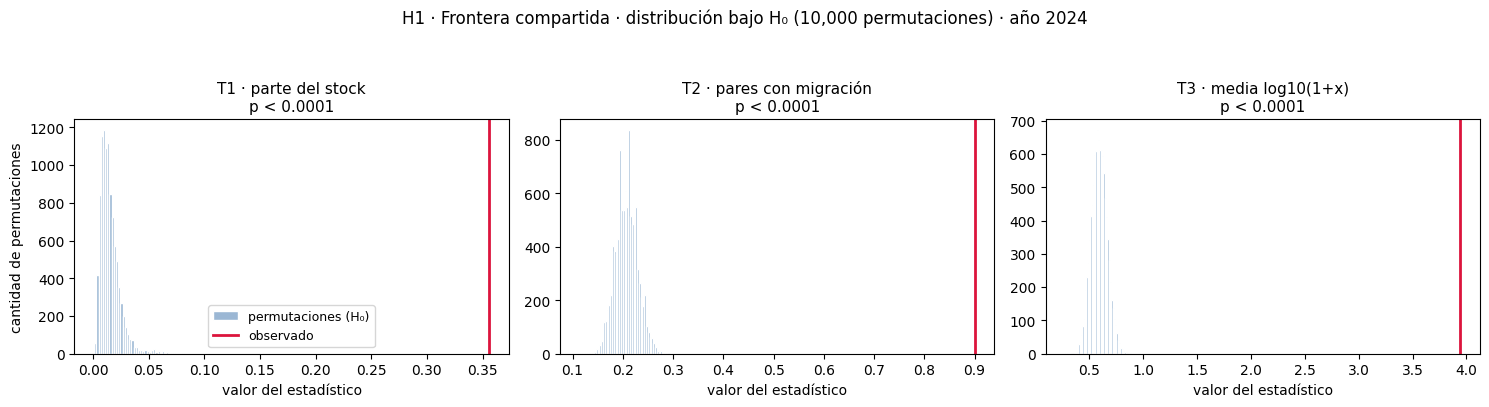

In [7]:
graficar_nulos(obs_h1, nulos_h1, "H1 · Frontera compartida")

## 1.3 Chequeos de robustez

1. **Test complementario de Mann-Whitney.** Compara la migración de los pares limítrofes con la de los no limítrofes ordenando todos los pares de menor a mayor. Su resultado más útil es el **AUC**: la probabilidad de que un par limítrofe elegido al azar tenga más migrantes que uno no limítrofe (0,5 = sin diferencia, 1 = siempre más). Su p-valor supone pares independientes, así que sale exageradamente chico y no se usa para decidir.
2. **Solo países continentales.** Las islas nunca tienen frontera terrestre y quedan siempre del lado "no limítrofe". Se repite el test sin ellas.
3. **Todos los años (1990-2024).** Para ver si el resultado se sostiene en el tiempo. Se usan 2.000 permutaciones por año para que no tarde demasiado.

In [8]:
# 1. Mann-Whitney (pares i != j)
off = ~np.eye(n, dtype=bool)
x_si, x_no = np.log10(1 + W[A & off]), np.log10(1 + W[~A & off])
u, p_mw = stats.mannwhitneyu(x_si, x_no, alternative="greater")
print(f"Mann-Whitney: AUC = {u / (len(x_si) * len(x_no)):.3f} · mediana de migrantes: limítrofes "
      f"{np.median(W[A & off]):,.0f} vs. no limítrofes {np.median(W[~A & off]):,.0f}")

# 2. Solo países continentales
cont = np.where(tipo == "continental")[0]
obs_c, nulos_c = qap(W[np.ix_(cont, cont)], A[np.ix_(cont, cont)])
print(f"\nSolo continentales ({len(cont)} países):")
display(resumen(obs_c, nulos_c).round(4))

# 3. Todos los años
filas_años = []
for a in años:
    o, nu = qap(W_por_año[a], A, n_perm=2_000)
    r = resumen(o, nu)
    filas_años.append(dict(año=a, **{f"ratio {t[:2]}": v for t, v in zip(NOMBRES_T, r["ratio_obs/nula"])},
                           **{f"p {t[:2]}": v for t, v in zip(NOMBRES_T, r["p_valor"])}))
print("Ratio observado / esperado bajo H₀ por año (1 = sin efecto de la frontera):")
display(pd.DataFrame(filas_años).set_index("año").round(4))

Mann-Whitney: AUC = 0.913 · mediana de migrantes: limítrofes 17,852 vs. no limítrofes 0

Solo continentales (156 países):


,estadístico,observado,media_nula,ratio_obs/nula,z,p_valor,rechaza_H0
0,T1 · parte del stock,0.4100,0.0259,15.8580,28.7252,0.0001,True
1,T2 · pares con migración,0.9003,0.2557,3.5216,31.4027,0.0001,True
2,T3 · media log10(1+x),3.9431,0.7623,5.1723,43.6712,0.0001,True


Ratio observado / esperado bajo H₀ por año (1 = sin efecto de la frontera):


,ratio T1,ratio T2,ratio T3,p T1,p T2,p T3
año,,,,,,
1990,34.0756,4.7583,7.7926,0.0005,0.0005,0.0005
1995,31.9258,4.6363,7.5343,0.0005,0.0005,0.0005
2000,30.3139,4.5703,7.3220,0.0005,0.0005,0.0005
2005,28.0476,4.5303,7.1248,0.0005,0.0005,0.0005
2010,26.1454,4.4299,6.9535,0.0005,0.0005,0.0005
2015,24.6256,4.3112,6.8331,0.0005,0.0005,0.0005
2020,23.7670,4.3176,6.6792,0.0005,0.0005,0.0005
2024,23.4556,4.3240,6.6404,0.0005,0.0005,0.0005


## 1.4 Cómo leer los resultados

- **p < 0,05 en T1, T2 y T3:** se rechaza H₀. Los pares limítrofes concentran más migración de la esperable si la frontera no importara, y `ratio_obs/nula` dice cuántas veces más.
- **p ≥ 0,05:** no se encontró evidencia de relación. Eso no prueba que no exista.
- **Límites:** la frontera viene junto con distancia corta, idioma e historia compartida, así que el test muestra asociación y no causalidad. Además, el dato es stock acumulado, no migraciones anuales.

---
# 2. Hipótesis 2 · Afinidad cultural

**Pregunta:** ¿las migraciones se concentran entre países con afinidad cultural? Se estudian dos casos: las migraciones con **origen en África** y las migraciones con **origen en la Commonwealth (CW)**.

- **H₀:** entre los países de origen del caso y sus destinos, el stock migratorio no tiene relación con la afinidad cultural del par.
- **H₁:** los pares con afinidad cultural tienen más migración que la esperable bajo H₀.

**Afinidad cultural.** Los dos casos usan el mismo criterio, como en el artículo. Un par tiene afinidad si cumple *cualquiera* de estas condiciones:
- comparten un idioma oficial,
- uno colonizó al otro,
- fueron colonizados por la misma potencia.

El idioma común cubre la mayoría de los lazos coloniales, pero no todos: hubo traspasos de colonias entre potencias y países que adoptaron otro idioma oficial. Por eso las condiciones se suman en un solo criterio en vez de quedarse solo con el idioma.

## Qué es igual a la hipótesis 1

El test es el mismo (sección 0.4): los mismos tres estadísticos, el mismo p-valor, los mismos gráficos y la misma función `qap`.

## Qué cambia

| | Hipótesis 1 | Hipótesis 2 (los dos casos) |
|---|---|---|
| **Pares estudiados** | Todos los pares de la red | Solo los que tienen **origen** en el grupo del caso (África o CW), hacia cualquier destino |
| **Vínculo** | Frontera compartida | Afinidad cultural |
| **Países incluidos** | Todos los de la tabla de la ONU | Solo los que tienen datos de idioma y coloniales (*universo común*) |
| **Permutación** | Global | **Por grupos**: los países del grupo se mezclan entre sí y el resto entre sí |

**Por qué se permuta por grupos.** En un test de permutación solo se intercambian los países que la hipótesis nula declara intercambiables. H₀ dice que la afinidad cultural no importa, pero no dice nada sobre ser africano o ser miembro de la CW: el grupo es una decisión de diseño, que define la población del estudio, y no parte del vínculo. Por eso los países del grupo y los de afuera no se intercambian.

Con una permutación global se confundirían dos efectos. Si la emigración del grupo se queda mayormente dentro del grupo (por cercanía o por historia compartida) y los pares afines también se concentran ahí, el test rechazaría H₀ aunque la afinidad no tuviera ningún efecto. En simulaciones con ese escenario, la permutación global dio entre 78% y 100% de falsos positivos; la permutación por grupos, alrededor del 5%. Permutar dentro de cada grupo deja fijo el reparto de la emigración entre destinos del grupo y destinos de afuera, y aísla el efecto de la afinidad.

**Cómo se hace.** Como en todo el notebook, la permutación se aplica a la matriz completa, con el mismo orden en filas y columnas, y después se toman las filas del grupo. La diferencia es que el orden se sortea dentro de cada grupo (parámetro `grupos` de `qap`): en las filas con etiqueta del grupo siempre quedan datos de países del grupo.

**Por qué un universo común.** Un país que no figura en una fuente es "sin dato", no "sin afinidad". Si se lo dejara con afinidad falsa, se inventarían pares sin vínculo que en realidad no se conocen. Las celdas listan qué países quedan afuera y por qué.

## 2.1 Datos de afinidad cultural

- **Idioma oficial en común:** dos países lo tienen si comparten al menos un idioma oficial o *de facto* oficial según el CLDR 48.2 de Unicode.
- **Lazos coloniales:** se toman de COLDAT (Becker, 2019), que registra las colonias de ocho potencias europeas: España, Portugal, Francia, Italia, Bélgica, Alemania, Países Bajos y Reino Unido. COLDAT identifica los países por nombre, así que se traducen a códigos con un diccionario. La celda imprime los nombres que no se pudieron traducir, para agregarlos.

In [9]:
# --- Idioma oficial en común (CLDR) ---
territorios = raiz_cldr.findall(".//territoryInfo/territory")
df_idioma = pd.DataFrame([
    {"iso2": t.get("type"), "idioma": l.get("type")}
    for t in territorios
    for l in t.findall("languagePopulation")
    if l.get("officialStatus") in ("official", "de_facto_official")
])
pares_idioma = df_idioma.merge(df_idioma, on="idioma")[["iso2_x", "iso2_y"]]
cob_idioma = actuales                      # países que figuran en el CLDR

# --- Lazos coloniales (COLDAT) ---
coldat = pd.read_csv(io.BytesIO(bytes_coldat), sep="\t")
nombre_a_iso2 = dict(zip(df_m49["pais_EN"], df_m49["iso2_m49"])) | {
    # nombres que en COLDAT figuran distinto que en m49.csv
    "Cape Verde": "CV", "Congo - Brazzaville": "CG", "Congo - Kinshasa": "CD", "São Tomé & Príncipe": "ST",
    "Tanzania": "TZ", "Antigua & Barbuda": "AG", "Bolivia": "BO", "St. Lucia": "LC", "Syria": "SY",
    "Trinidad & Tobago": "TT", "United States": "US", "Venezuela": "VE", "Brunei": "BN",
    "Myanmar (Burma)": "MM", "Nauru": "NR", "St. Kitts & Nevis": "KN", "St. Vincent & Grenadines": "VC",
    "Laos": "LA", "Vietnam": "VN",
    # probables nombres de países que sin esto quedan "sin datos"; si alguno no coincide, no afecta
    "Iran": "IR", "South Korea": "KR", "North Korea": "KP", "Moldova": "MD", "Russia": "RU",
    "Turkey": "TR", "Türkiye": "TR", "Bosnia & Herzegovina": "BA", "Palestinian Territories": "PS",
    "Hong Kong SAR China": "HK", "Macao SAR China": "MO", "Vatican City": "VA",
}
potencia_a_iso2 = {"belgium": "BE", "britain": "GB", "france": "FR", "germany": "DE",
                   "netherlands": "NL", "portugal": "PT", "spain": "ES", "italy": "IT"}

coldat["iso2_pais"] = coldat["country"].map(nombre_a_iso2)
colonias = coldat[coldat["col"] == 1].copy()
colonias["iso2_colonizador"] = colonias["colonizer"].map(potencia_a_iso2)
print("Colonias que no se pudieron traducir a código (agregar al diccionario):",
      sorted(colonias.loc[colonias["iso2_pais"].isna(), "country"].unique()))
colonias = colonias.dropna(subset=["iso2_pais", "iso2_colonizador"])

pares_metropoli = colonias.merge(colonias, on="iso2_colonizador")[["iso2_pais_x", "iso2_pais_y"]]
cob_colonial = set(coldat["iso2_pais"].dropna()) | set(colonias["iso2_colonizador"])

print(f"Idiomas oficiales: {df_idioma['idioma'].nunique()} · díadas colonia-potencia: {len(colonias)}")

Colonias que no se pudieron traducir a código (agregar al diccionario): []
Idiomas oficiales: 125 · díadas colonia-potencia: 161


In [10]:
def matriz_vinculo(a, b, universo, simetrica=True):
    """Matriz booleana de pares (a[k], b[k]) sobre una lista de países (ISO2)."""
    idx = {iso: k for k, iso in enumerate(universo)}
    ok = (a.isin(idx) & b.isin(idx)).to_numpy()
    M = np.zeros((len(universo), len(universo)), dtype=bool)
    M[a[ok].map(idx).to_numpy(), b[ok].map(idx).to_numpy()] = True
    if simetrica:
        M |= M.T
    np.fill_diagonal(M, False)
    return M

def tabla_afinidad(universo, filas, criterios, W_sub, grupos, rotulo):
    """Duplas (origen del caso, cualquier destino) con cada criterio y la afinidad combinada."""
    o, d = np.meshgrid(filas, np.arange(len(universo)), indexing="ij")
    o, d = o.ravel(), d.ravel()
    o, d = o[o != d], d[o != d]
    t = pd.DataFrame({"iso2_orig": np.asarray(universo)[o], "iso2_des": np.asarray(universo)[d],
                      f"destino_{rotulo}": grupos[d] == rotulo})
    for nombre, M in criterios.items():
        t[nombre] = M[o, d]
    t["afinidad_cultural"] = t[list(criterios)].any(axis=1)
    t["migrantes"] = W_sub[o, d]
    return t

def describir_afinidad(t, extra=None):
    print(f"Pares del caso: {len(t):,} · con afinidad cultural: {t['afinidad_cultural'].sum():,} "
          f"({t['afinidad_cultural'].mean():.1%})")
    print(f"Parte del stock del caso que va a pares con afinidad: "
          f"{t.loc[t['afinidad_cultural'], 'migrantes'].sum() / t['migrantes'].sum():.1%}")
    if extra:
        print(extra)

## 2.2 Universo y matriz de afinidad

La matriz de afinidad es la misma para los dos casos. Se arma una vez sobre el universo común; cada caso solo elige sus filas de origen.

In [11]:
universo_h2 = [i for i in nodos if i in cob_idioma and i in cob_colonial]
print(f"Universo: {len(universo_h2)} de {len(nodos)} países")
print("  sin datos de idioma:", sorted(set(nodos) - cob_idioma))
print("  sin datos coloniales:", sorted(set(nodos) - cob_colonial))

criterios = {
    "idioma_comun":     matriz_vinculo(pares_idioma["iso2_x"], pares_idioma["iso2_y"], universo_h2),
    "vinculo_colonial": matriz_vinculo(colonias["iso2_colonizador"], colonias["iso2_pais"], universo_h2),
    "misma_potencia":   matriz_vinculo(pares_metropoli["iso2_pais_x"], pares_metropoli["iso2_pais_y"], universo_h2),
}
C_afinidad = np.logical_or.reduce(list(criterios.values()))     # afinidad cultural = cualquiera de los tres
W_h2 = submatriz(universo_h2)

def preparar_caso(miembros, rotulo):
    """Grupos (rótulo / resto), filas de origen y tabla de duplas de un caso."""
    es = np.array([i in miembros for i in universo_h2])
    grupos = np.where(es, rotulo, "resto")
    filas = np.where(es)[0]
    tabla = tabla_afinidad(universo_h2, filas, criterios, W_h2, grupos, rotulo)
    return grupos, filas, tabla

Universo: 194 de 202 países
  sin datos de idioma: []
  sin datos coloniales: ['AW', 'CW', 'GL', 'HK', 'MO', 'PS', 'SX', 'VA']


## 2.3 Caso África

El grupo son los países de la región África según la clasificación M49.

In [12]:
africa = set(df_m49.loc[df_m49["region_EN"] == "Africa", "iso2_m49"])
grupos_af, af, afinidad_cultural_africa = preparar_caso(africa, "África")

t = afinidad_cultural_africa
describir_afinidad(t, f"Pares con afinidad colonial pero sin idioma común: {(t['afinidad_cultural'] & ~t['idioma_comun']).sum():,}")
print(f"Países africanos de origen: {len(af)}")
afinidad_cultural_africa.head()

Pares del caso: 10,422 · con afinidad cultural: 3,473 (33.3%)
Parte del stock del caso que va a pares con afinidad: 77.5%
Pares con afinidad colonial pero sin idioma común: 929
Países africanos de origen: 54


,iso2_orig,iso2_des,destino_África,idioma_comun,vinculo_colonial,misma_potencia,afinidad_cultural,migrantes
0,AO,AD,False,False,False,False,False,0.0
1,AO,AE,False,False,False,False,False,0.0
2,AO,AF,False,False,False,False,False,0.0
3,AO,AG,False,False,False,False,False,0.0
4,AO,AL,False,False,False,False,False,0.0


In [13]:
obs_af, nulos_af = qap(W_h2, C_afinidad, filas=af, grupos=grupos_af)   # origen africano -> todos, por grupos
res_af = resumen(obs_af, nulos_af)
res_af.round(4)

,estadístico,observado,media_nula,ratio_obs/nula,z,p_valor,rechaza_H0
0,T1 · parte del stock,0.7748,0.4080,1.8990,5.2302,0.0001,True
1,T2 · pares con migración,0.2171,0.2022,1.0738,0.9320,0.1812,False
2,T3 · media log10(1+x),0.7378,0.5804,1.2712,3.6375,0.0002,True


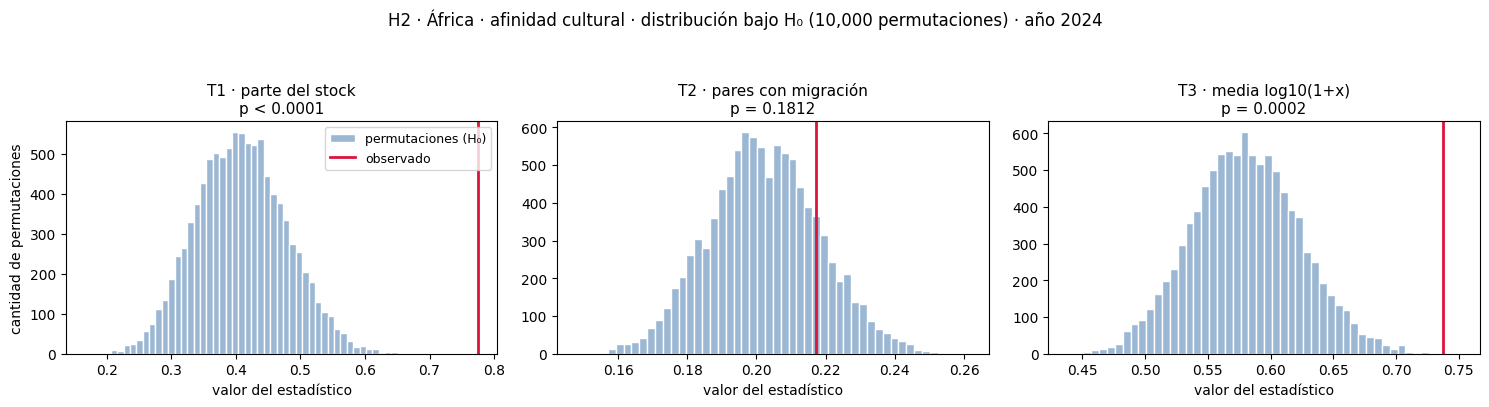

In [14]:
graficar_nulos(obs_af, nulos_af, "H2 · África · afinidad cultural")

## 2.4 Caso Commonwealth

El grupo son los 56 miembros actuales de la CW, para todo el período. El criterio de afinidad y la permutación son los mismos que en África: solo cambia el grupo de origen.

El vínculo colonial casi coincide con la pertenencia: 52 de los 56 miembros fueron parte del Imperio Británico. Por eso casi todos los pares entre miembros tienen afinidad por "misma potencia", y los pares Reino Unido-ex colonia la tienen por "vínculo colonial" en las dos direcciones (también cuenta la migración desde el Reino Unido hacia sus ex colonias, porque el Reino Unido es miembro y por lo tanto origen).

In [15]:
LISTA_MIEMBROS_CW = [
    'BW','CM','GA','GM','GH','KE','SZ','LS','MW','MU','MZ','NA','NG','RW','SC','SL','ZA','TG','UG','TZ','ZM',  # África
    'BD','BN','IN','MY','MV','PK','SG','LK',                                                                    # Asia
    'AG','BS','BB','BZ','CA','DM','GD','GY','JM','LC','KN','VC','TT',                                          # América
    'CY','MT','GB',                                                                                             # Europa
    'AU','FJ','KI','NR','NZ','PG','WS','SB','TO','TV','VU',                                                     # Oceanía
]
print("Miembros fuera del universo:", sorted(set(LISTA_MIEMBROS_CW) - set(universo_h2)))
grupos_cw, cw, afinidad_cultural_cw = preparar_caso(set(LISTA_MIEMBROS_CW), "CW")

t = afinidad_cultural_cw
intra = t["destino_CW"]
describir_afinidad(t, f"Pares entre miembros con afinidad: {t.loc[intra, 'afinidad_cultural'].mean():.1%} · "
                      f"pares hacia afuera de la CW con afinidad: {t.loc[~intra, 'afinidad_cultural'].mean():.1%}")
print(f"Miembros de origen: {len(cw)}")
afinidad_cultural_cw.head()

Miembros fuera del universo: []
Pares del caso: 10,808 · con afinidad cultural: 4,562 (42.2%)
Parte del stock del caso que va a pares con afinidad: 73.9%
Pares entre miembros con afinidad: 90.1% · pares hacia afuera de la CW con afinidad: 23.1%
Miembros de origen: 56


,iso2_orig,iso2_des,destino_CW,idioma_comun,vinculo_colonial,misma_potencia,afinidad_cultural,migrantes
0,AG,AD,False,False,False,False,False,0.0
1,AG,AE,False,False,False,True,True,0.0
2,AG,AF,False,False,False,False,False,0.0
3,AG,AL,False,False,False,False,False,0.0
4,AG,AM,False,False,False,False,False,0.0


In [16]:
obs_cw, nulos_cw = qap(W_h2, C_afinidad, filas=cw, grupos=grupos_cw)   # origen en la CW -> todos, por grupos
res_cw = resumen(obs_cw, nulos_cw)
res_cw.round(4)

,estadístico,observado,media_nula,ratio_obs/nula,z,p_valor,rechaza_H0
0,T1 · parte del stock,0.7391,0.4978,1.4845,2.6770,0.0061,True
1,T2 · pares con migración,0.1957,0.2020,0.9691,-0.5219,0.6940,False
2,T3 · media log10(1+x),0.5927,0.5570,1.0641,1.2487,0.1053,False


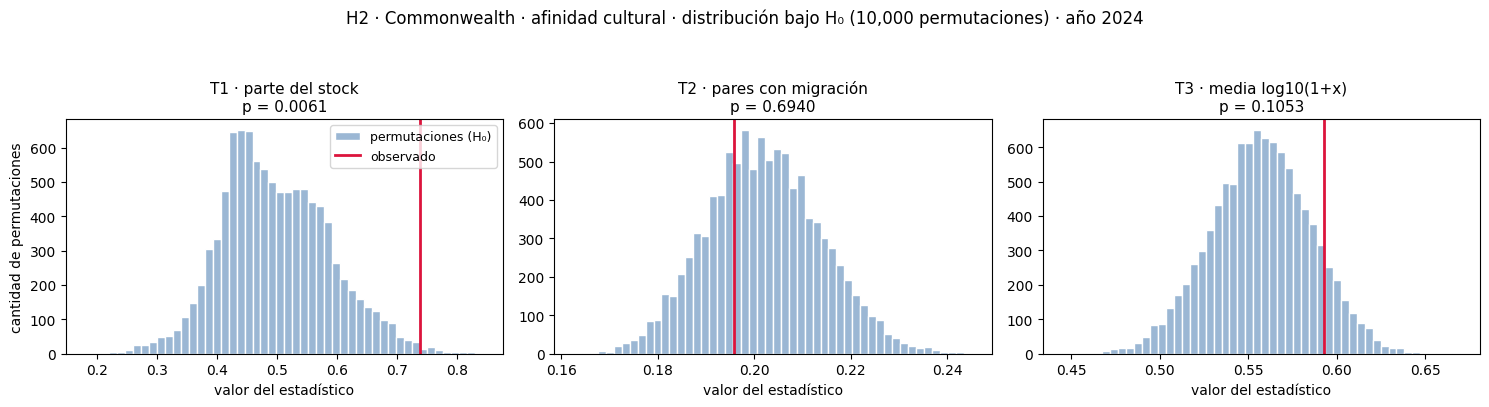

In [17]:
graficar_nulos(obs_cw, nulos_cw, "H2 · Commonwealth · afinidad cultural")

## 2.5 Cómo leer los resultados

- Se lee igual que la hipótesis 1. Si los tres estadísticos rechazan H₀, la migración que sale del grupo se concentra en los destinos con afinidad cultural más de lo esperable por azar.
- **Qué controla la permutación por grupos.** El reparto de la emigración entre destinos del grupo y de afuera queda fijo. El test responde si, dentro de esa estructura, los emigrantes eligen los destinos afines; no responde si el grupo migra más hacia adentro que hacia afuera.
- **En la CW, el contraste viene sobre todo de los destinos de afuera.** Como casi todos los pares entre miembros tienen afinidad, dentro de la CW hay poco con qué comparar. El resultado depende principalmente de si los emigrantes de la CW, cuando salen del grupo, eligen destinos con idioma o lazo colonial en común.
- **El criterio combinado no dice cuál de las condiciones pesa más.** Idioma y pasado colonial están muy mezclados.
- **Frontera y afinidad también se solapan.** Muchos pares afines son vecinos. Para separar los efectos haría falta un test con varios vínculos a la vez (MRQAP).

---
# 3. Hipótesis 3 · Asimetría económica

**Pregunta:** ¿las migraciones van de un país hacia otro más desarrollado?

- **H₀:** la dirección de la migración no tiene relación con la diferencia de desarrollo entre origen y destino.
- **H₁:** hay más migración hacia destinos más desarrollados que hacia destinos menos desarrollados.

**Medida de desarrollo:** PBI per cápita a paridad de poder adquisitivo, en dólares internacionales constantes de 2021 (Banco Mundial, indicador `NY.GDP.PCAP.PP.KD`), el mismo que usa el artículo. Para cada país se toma el valor de `AÑO_PRINCIPAL` o, si falta, el último disponible dentro de los tres años anteriores.

## Qué es igual a la hipótesis 1

Se estudian todos los pares de la red y la permutación es global. El test, los estadísticos y los gráficos son los mismos.

## Qué cambia

- **El vínculo es dirigido.** `C[i, j]` es verdadero si el destino `j` tiene mayor PBI per cápita que el origen `i` (más de `RATIO_MIN` veces). En la frontera y en la afinidad, `C[i, j]` y `C[j, i]` son iguales. Acá son opuestos: de cada par de países, una sola dirección es "hacia arriba".
- **La referencia bajo H₀ es cercana a la mitad.** Con `RATIO_MIN = 1`, la mitad de los pares dirigidos son "hacia arriba". Si la dirección no importara, T1 rondaría el 50% del stock; `ratio_obs/nula` compara el valor real con esa referencia.
- **Universo:** países con dato de PBI per cápita del Banco Mundial.

Con `RATIO_MIN` mayor que 1 (por ejemplo 2), solo cuentan los destinos al menos el doble de ricos y los pares parecidos no tienen vínculo en ninguna dirección. Sirve como chequeo de robustez.

In [39]:
RATIO_MIN = 2.0   # el destino cuenta como "más desarrollado" si su PBI pc es mayor que RATIO_MIN x el del origen

def bajar_banco_mundial(indicador):
    """Serie 1990-2024 de un indicador del Banco Mundial para todos los países (recorre todas las páginas)."""
    registros, pagina = [], 1
    while True:
        url = f"{URL_BM}/{indicador}?format=json&date=1990:2024&per_page=20000&page={pagina}"
        meta, datos = json.loads(descargar(url, f"Banco Mundial {indicador} (página {pagina})"))
        registros += datos or []
        if pagina >= int(meta["pages"]):
            break
        pagina += 1
    return pd.DataFrame({
        "iso2": [r["country"]["id"] for r in registros],
        "año": [int(r["date"]) for r in registros],
        "valor": [r["value"] for r in registros],
    }).dropna()

df_pib = bajar_banco_mundial("NY.GDP.PCAP.PP.KD")
año = int(AÑO_PRINCIPAL)
pib = (df_pib[(df_pib["año"] <= año) & (df_pib["año"] >= año - 3)]
       .sort_values("año").groupby("iso2")["valor"].last().to_dict())

OK  Banco Mundial NY.GDP.PCAP.PP.KD (página 1): 2.31 MB


In [40]:
universo_h3 = [i for i in nodos if i in pib]
print(f"Universo: {len(universo_h3)} de {len(nodos)} países · sin dato de PBI per cápita: "
      f"{sorted(set(nodos) - set(pib))}")

pib_u = np.array([pib[i] for i in universo_h3])
C_h3 = pib_u[None, :] > RATIO_MIN * pib_u[:, None]       # C[i, j]: el destino j es más rico que el origen i
np.fill_diagonal(C_h3, False)
W_h3 = submatriz(universo_h3)

m = len(C_h3)
print(f"Pares dirigidos 'hacia arriba': {C_h3.sum() / (m * (m - 1)):.1%} de los pares posibles")
print(f"Parte del stock que va hacia un país más rico: {W_h3[C_h3].sum() / W_h3.sum():.1%}")

Universo: 192 de 202 países · sin dato de PBI per cápita: ['CU', 'ER', 'KP', 'LI', 'MC', 'SS', 'TW', 'VA', 'VE', 'YE']
Pares dirigidos 'hacia arriba': 34.1% de los pares posibles
Parte del stock que va hacia un país más rico: 64.0%


In [41]:
obs_h3, nulos_h3 = qap(W_h3, C_h3)       # todos los pares, permutación global
res_h3 = resumen(obs_h3, nulos_h3)
res_h3.round(4)

,estadístico,observado,media_nula,ratio_obs/nula,z,p_valor,rechaza_H0
0,T1 · parte del stock,0.6397,0.3411,1.8753,5.0009,0.0001,True
1,T2 · pares con migración,0.2533,0.2126,1.1914,3.1798,0.0009,True
2,T3 · media log10(1+x),0.7293,0.6121,1.1915,3.4938,0.0003,True


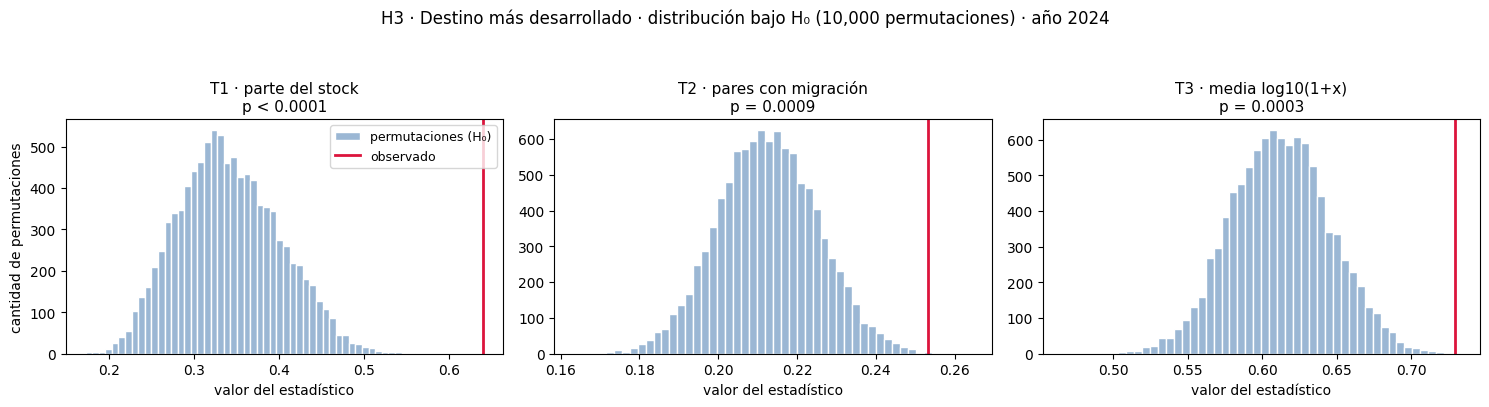

In [42]:
graficar_nulos(obs_h3, nulos_h3, "H3 · Destino más desarrollado")

## 3.1 Cómo leer los resultados

- Si se rechaza H₀, la migración va hacia países más ricos más de lo esperable si la dirección no importara.
- **El PBI per cápita es una medida parcial del desarrollo.** Una alternativa es el Índice de Desarrollo Humano (IDH); el código sirve igual cambiando la fuente de `pib`.
- **El stock arrastra historia.** Refleja migraciones de décadas, no solo las actuales. El artículo muestra el ejemplo del corredor Argentina-España, que se invirtió entre 1990 y 2024 a medida que creció la brecha económica.
- **Asociación, no causalidad.** Los países ricos también suelen tener más población, redes de compatriotas ya instaladas y otros atractivos que no son el ingreso.

---
# 4. Resumen de resultados

In [43]:
casos = {
    ("H1", "Frontera compartida (todos los pares)"): res_h1,
    ("H2", "Afinidad cultural · origen en África"): res_af,
    ("H2", "Afinidad cultural · origen en la Commonwealth"): res_cw,
    ("H3", "Destino más desarrollado (todos los pares)"): res_h3,
}
resumen_final = pd.concat(
    [r.assign(hipótesis=h, caso=c) for (h, c), r in casos.items()], ignore_index=True
)[["hipótesis", "caso", "estadístico", "observado", "media_nula", "ratio_obs/nula", "p_valor", "rechaza_H0"]]
print(f"Año {AÑO_PRINCIPAL} · {N_PERM:,} permutaciones por test · α = {ALFA}")
resumen_final.round(4)

Año 2024 · 10,000 permutaciones por test · α = 0.05


,hipótesis,caso,estadístico,observado,media_nula,ratio_obs/nula,p_valor,rechaza_H0
0,H1,Frontera compartida (todos los pares),T1 · parte del stock,0.3559,0.0151,23.5272,0.0001,True
1,H1,Frontera compartida (todos los pares),T2 · pares con migración,0.9003,0.2072,4.3449,0.0001,True
2,H1,Frontera compartida (todos los pares),T3 · media log10(1+x),3.9431,0.5904,6.6784,0.0001,True
3,H2,Afinidad cultural · origen en África,T1 · parte del stock,0.7748,0.4080,1.8990,0.0001,True
4,H2,Afinidad cultural · origen en África,T2 · pares con migración,0.2171,0.2022,1.0738,0.1812,False
5,H2,Afinidad cultural · origen en África,T3 · media log10(1+x),0.7378,0.5804,1.2712,0.0002,True
6,H2,Afinidad cultural · origen en la Commonwealth,T1 · parte del stock,0.7391,0.4978,1.4845,0.0061,True
7,H2,Afinidad cultural · origen en la Commonwealth,T2 · pares con migración,0.1957,0.2020,0.9691,0.6940,False
8,H2,Afinidad cultural · origen en la Commonwealth,T3 · media log10(1+x),0.5927,0.5570,1.0641,0.1053,False
9,H3,Destino más desarrollado (todos los pares),T1 · parte del stock,0.6397,0.3411,1.8753,0.0001,True
